# 05 — Ensemble Learning

Treinamento de **Random Forest** e **Gradient Boosting**. Os dois são avaliados nos mesmos conjuntos de treino e
teste dos notebooks anteriores.

* Random Forest: várias árvores treinadas em amostras *bootstrap* com seleção
  aleatória de variáveis; a média/voto reduz a variância.
* Gradient Boosting: árvores sequenciais, cada uma corrigindo o erro residual
  das anteriores; reduz o viés, mas exige controle da taxa de aprendizado.

In [1]:
from pathlib import Path
import sys
import warnings

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import *
from src.prepare_data import preparar_classificacao, preparar_regressao
from src.metrics import calcular_metricas_classificacao, calcular_metricas_regressao
from src.models import (
    GRADE_GB_CLASSIFICACAO,
    GRADE_GB_REGRESSAO,
    GRADE_RF_CLASSIFICACAO,
    GRADE_RF_REGRESSAO,
    buscar_hiperparametros,
    criar_gradient_boosting_classificacao,
    criar_gradient_boosting_regressao,
    criar_random_forest_classificacao,
    criar_random_forest_regressao,
    importancias_features,
    salvar_modelo,
)
from src.visualization import plotar_importancia_features, plotar_residuos

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
criar_diretorios()

X_train_c, X_test_c, y_train_c, y_test_c = preparar_classificacao()
X_train_r, X_test_r, y_train_r, y_test_r = preparar_regressao()

print("Classificação:", X_train_c.shape, X_test_c.shape)
print("Regressão:    ", X_train_r.shape, X_test_r.shape)

Classificação: (40000, 9) (10000, 9)
Regressão:     (40000, 8) (10000, 8)


## 1. Curva de erro da Random Forest em função do número de árvores

,n_arvores,Erro classificação treino,Erro classificação teste,MAE regressão treino,MAE regressão teste
0,1,0.0683,0.1890,3.1734,8.6542
1,10,0.0101,0.1425,2.5604,6.5331
2,50,0.0004,0.1327,2.3581,6.3633
3,100,0.0000,0.1317,2.3305,6.3301
4,200,0.0000,0.1326,2.3182,6.3177


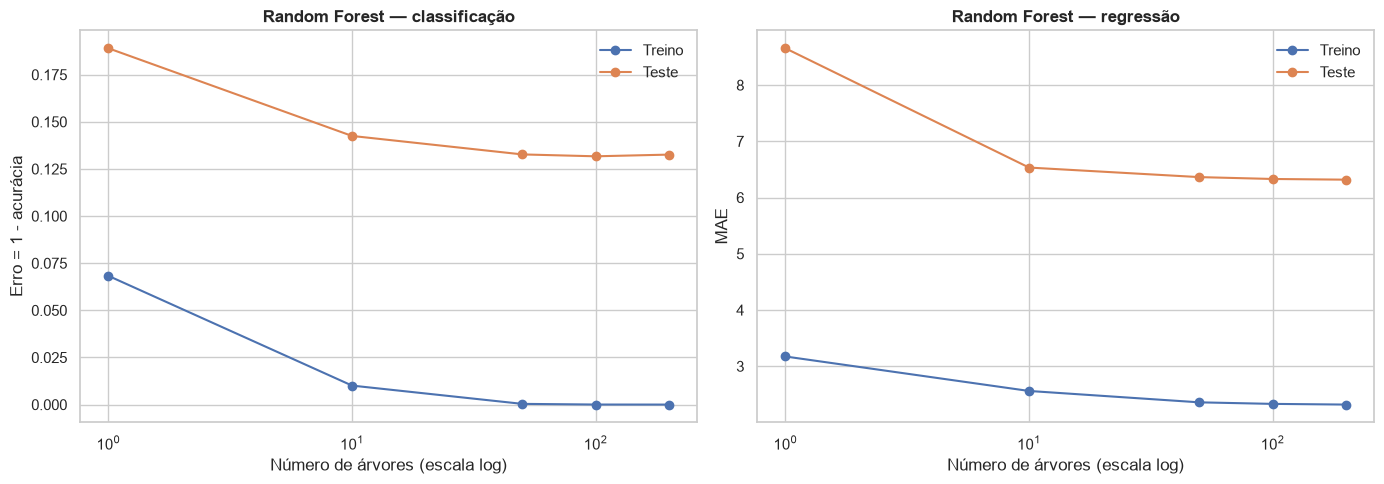

In [2]:
numeros_arvores = [1, 10, 50, 100, 200]
registros_curva = []

for n in numeros_arvores:
    rf_c = criar_random_forest_classificacao(n_estimators=n)
    rf_c.fit(X_train_c, y_train_c)
    erro_treino = 1 - rf_c.score(X_train_c, y_train_c)
    erro_teste = 1 - rf_c.score(X_test_c, y_test_c)

    rf_r = criar_random_forest_regressao(n_estimators=n)
    rf_r.fit(X_train_r, y_train_r)
    mae_treino = np.mean(np.abs(y_train_r - rf_r.predict(X_train_r)))
    mae_teste = np.mean(np.abs(y_test_r - rf_r.predict(X_test_r)))

    registros_curva.append(
        {
            "n_arvores": n,
            "Erro classificação treino": erro_treino,
            "Erro classificação teste": erro_teste,
            "MAE regressão treino": mae_treino,
            "MAE regressão teste": mae_teste,
        }
    )

curva_rf = pd.DataFrame(registros_curva)
display(curva_rf.round(4))
curva_rf.to_csv(TABLES_DIR / "curva_erro_rf.csv", index=False, encoding="utf-8")

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))

eixos[0].plot(curva_rf["n_arvores"], curva_rf["Erro classificação treino"], marker="o", label="Treino")
eixos[0].plot(curva_rf["n_arvores"], curva_rf["Erro classificação teste"], marker="o", label="Teste")
eixos[0].set_xscale("log")
eixos[0].set_xlabel("Número de árvores (escala log)")
eixos[0].set_ylabel("Erro = 1 - acurácia")
eixos[0].set_title("Random Forest — classificação", fontweight="bold")
eixos[0].legend()

eixos[1].plot(curva_rf["n_arvores"], curva_rf["MAE regressão treino"], marker="o", label="Treino")
eixos[1].plot(curva_rf["n_arvores"], curva_rf["MAE regressão teste"], marker="o", label="Teste")
eixos[1].set_xscale("log")
eixos[1].set_xlabel("Número de árvores (escala log)")
eixos[1].set_ylabel("MAE")
eixos[1].set_title("Random Forest — regressão", fontweight="bold")
eixos[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "curva_erro_random_forest.png", dpi=300, bbox_inches="tight")
plt.show()

Com poucas árvores o erro de teste é alto e instável. A partir de algumas
dezenas de árvores a curva se estabiliza: a média de árvores pouco
correlacionadas reduz a variância sem aumentar muito o viés. O erro de treino
sobe ligeiramente (cada árvore vê uma amostra bootstrap), o que é esperado e
saudável. Mais árvores melhoram a estabilidade, mas com retorno decrescente e
custo computacional linear.

## 2. Ajuste da Random Forest

In [3]:
busca_rf_c = buscar_hiperparametros(
    criar_random_forest_classificacao(),
    GRADE_RF_CLASSIFICACAO,
    X_train_c,
    y_train_c,
    problema="classificacao",
    scoring="f1_macro",
    n_jobs=1,  # o Random Forest já usa n_jobs=-1 internamente
)
rf_c = busca_rf_c.best_estimator_
rf_c.fit(X_train_c, y_train_c)

print("Melhores hiperparâmetros (classificação):", busca_rf_c.best_params_)
print(f"F1 macro na validação cruzada: {busca_rf_c.best_score_:.4f}")

pred_c_treino = rf_c.predict(X_train_c)
pred_c_teste = rf_c.predict(X_test_c)
metricas_rf_c = pd.DataFrame(
    {
        "Treino": calcular_metricas_classificacao(
            y_train_c, pred_c_treino, classes=CLASSES, classe_positiva=CLASSE_POSITIVA
        ),
        "Teste": calcular_metricas_classificacao(
            y_test_c, pred_c_teste, classes=CLASSES, classe_positiva=CLASSE_POSITIVA
        ),
    }
)
display(metricas_rf_c.round(4))
salvar_modelo(rf_c, "rf_classificacao")

Melhores hiperparâmetros (classificação): {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
F1 macro na validação cruzada: 0.6838


,Treino,Teste
Accuracy,1.0,0.8678
Precision (Macro),1.0,0.7786
Recall (Macro),1.0,0.6460
F1-Score (Macro),1.0,0.6862
Precision (Weighted),1.0,0.8650
Recall (Weighted),1.0,0.8678
F1-Score (Weighted),1.0,0.8655
Precision (High),1.0,0.9066
Recall (High),1.0,0.9257
F1-Score (High),1.0,0.9160


WindowsPath('C:/Users/lucas/OneDrive/Documentos/avaliacao-comparativa-modelos-ia/artifacts/models/rf_classificacao.joblib')

In [4]:
busca_rf_r = buscar_hiperparametros(
    criar_random_forest_regressao(),
    GRADE_RF_REGRESSAO,
    X_train_r,
    y_train_r,
    problema="regressao",
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
)
rf_r = busca_rf_r.best_estimator_
rf_r.fit(X_train_r, y_train_r)

print("Melhores hiperparâmetros (regressão):", busca_rf_r.best_params_)
print(f"RMSE na validação cruzada: {-busca_rf_r.best_score_:.4f}")

metricas_rf_r = pd.DataFrame(
    {
        "Treino": calcular_metricas_regressao(y_train_r, rf_r.predict(X_train_r)),
        "Teste": calcular_metricas_regressao(y_test_r, rf_r.predict(X_test_r)),
    }
)
display(metricas_rf_r.round(4))
salvar_modelo(rf_r, "rf_regressao")

Melhores hiperparâmetros (regressão): {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
RMSE na validação cruzada: 7.6404


,Treino,Teste
MAE,4.5915,6.1402
MSE,33.5011,58.7201
RMSE,5.7880,7.6629
MAPE (%),6.7422,8.9851
R2,0.8626,0.7569
MedAE,3.8359,5.2245


WindowsPath('C:/Users/lucas/OneDrive/Documentos/avaliacao-comparativa-modelos-ia/artifacts/models/rf_regressao.joblib')

## 3. Ajuste do Gradient Boosting

In [5]:
busca_gb_c = buscar_hiperparametros(
    criar_gradient_boosting_classificacao(),
    GRADE_GB_CLASSIFICACAO,
    X_train_c,
    y_train_c,
    problema="classificacao",
    scoring="f1_macro",
    n_jobs=-1,
)
gb_c = busca_gb_c.best_estimator_
gb_c.fit(X_train_c, y_train_c)

print("Melhores hiperparâmetros (classificação):", busca_gb_c.best_params_)
print(f"F1 macro na validação cruzada: {busca_gb_c.best_score_:.4f}")

metricas_gb_c = pd.DataFrame(
    {
        "Treino": calcular_metricas_classificacao(
            y_train_c, gb_c.predict(X_train_c), classes=CLASSES, classe_positiva=CLASSE_POSITIVA
        ),
        "Teste": calcular_metricas_classificacao(
            y_test_c, gb_c.predict(X_test_c), classes=CLASSES, classe_positiva=CLASSE_POSITIVA
        ),
    }
)
display(metricas_gb_c.round(4))
salvar_modelo(gb_c, "gb_classificacao")

Melhores hiperparâmetros (classificação): {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
F1 macro na validação cruzada: 0.7126


,Treino,Teste
Accuracy,0.8860,0.8790
Precision (Macro),0.8482,0.7540
Recall (Macro),0.7001,0.6326
F1-Score (Macro),0.7506,0.6681
Precision (Weighted),0.8834,0.8751
Recall (Weighted),0.8860,0.8790
F1-Score (Weighted),0.8836,0.8760
Precision (High),0.9129,0.9117
Recall (High),0.9427,0.9377
F1-Score (High),0.9276,0.9245


WindowsPath('C:/Users/lucas/OneDrive/Documentos/avaliacao-comparativa-modelos-ia/artifacts/models/gb_classificacao.joblib')

In [6]:
busca_gb_r = buscar_hiperparametros(
    criar_gradient_boosting_regressao(),
    GRADE_GB_REGRESSAO,
    X_train_r,
    y_train_r,
    problema="regressao",
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
gb_r = busca_gb_r.best_estimator_
gb_r.fit(X_train_r, y_train_r)

print("Melhores hiperparâmetros (regressão):", busca_gb_r.best_params_)
print(f"RMSE na validação cruzada: {-busca_gb_r.best_score_:.4f}")

metricas_gb_r = pd.DataFrame(
    {
        "Treino": calcular_metricas_regressao(y_train_r, gb_r.predict(X_train_r)),
        "Teste": calcular_metricas_regressao(y_test_r, gb_r.predict(X_test_r)),
    }
)
display(metricas_gb_r.round(4))
salvar_modelo(gb_r, "gb_regressao")

Melhores hiperparâmetros (regressão): {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}
RMSE na validação cruzada: 7.3797


,Treino,Teste
MAE,5.8817,5.9278
MSE,53.7615,54.4626
RMSE,7.3322,7.3799
MAPE (%),8.6010,8.6523
R2,0.7794,0.7745
MedAE,5.0082,5.0677


WindowsPath('C:/Users/lucas/OneDrive/Documentos/avaliacao-comparativa-modelos-ia/artifacts/models/gb_regressao.joblib')

## 4. Comparação rápida dos ensembles

As duas famílias têm filosofias diferentes: a Random Forest reduz a variância
pela média de árvores independentes; o Gradient Boosting reduz o viés somando
árvores sequenciais. Em geral o boosting alcança erro menor, mas é mais
sensível a hiperparâmetros e mais difícil de paralelizar no treino.

In [7]:
resumo_ensembles = pd.DataFrame(
    [
        {
            "Modelo": "Random Forest — classificação",
            "F1 Macro Teste": metricas_rf_c.loc["F1-Score (Macro)", "Teste"],
            "F1 High Teste": metricas_rf_c.loc["F1-Score (High)", "Teste"],
            "Accuracy Teste": metricas_rf_c.loc["Accuracy", "Teste"],
        },
        {
            "Modelo": "Gradient Boosting — classificação",
            "F1 Macro Teste": metricas_gb_c.loc["F1-Score (Macro)", "Teste"],
            "F1 High Teste": metricas_gb_c.loc["F1-Score (High)", "Teste"],
            "Accuracy Teste": metricas_gb_c.loc["Accuracy", "Teste"],
        },
    ]
)
display(resumo_ensembles.round(4))

resumo_ensembles_r = pd.DataFrame(
    [
        {
            "Modelo": "Random Forest — regressão",
            "MAE Teste": metricas_rf_r.loc["MAE", "Teste"],
            "RMSE Teste": metricas_rf_r.loc["RMSE", "Teste"],
            "R2 Teste": metricas_rf_r.loc["R2", "Teste"],
        },
        {
            "Modelo": "Gradient Boosting — regressão",
            "MAE Teste": metricas_gb_r.loc["MAE", "Teste"],
            "RMSE Teste": metricas_gb_r.loc["RMSE", "Teste"],
            "R2 Teste": metricas_gb_r.loc["R2", "Teste"],
        },
    ]
)
display(resumo_ensembles_r.round(4))

,Modelo,F1 Macro Teste,F1 High Teste,Accuracy Teste
0,Random Forest — classificação,0.6862,0.9160,0.8678
1,Gradient Boosting — classificação,0.6681,0.9245,0.8790


,Modelo,MAE Teste,RMSE Teste,R2 Teste
0,Random Forest — regressão,6.1402,7.6629,0.7569
1,Gradient Boosting — regressão,5.9278,7.3799,0.7745


## 5. Importância das variáveis

,Feature,RF classificação,GB classificação,RF regressão,GB regressão
0,Age,0.1479,0.1038,0.1165,0.1073
1,BMI,0.1543,0.0740,0.1004,0.0821
2,Diet_Quality,0.0471,0.0305,0.0363,0.0374
3,Family_History_Diabetes,0.0521,0.1057,0.1091,0.1202
4,Fasting_Blood_Sugar,0.3018,0.3689,0.3441,0.3546
5,HbA1c,0.2036,0.2335,0.2159,0.2166
6,Heart_Disease,0.0314,0.0261,NaN,NaN
7,Hypertension,0.0316,0.0325,0.0392,0.0436
8,PCOS,0.0302,0.0250,NaN,NaN
9,Physical_Activity_Level,NaN,NaN,0.0384,0.0383


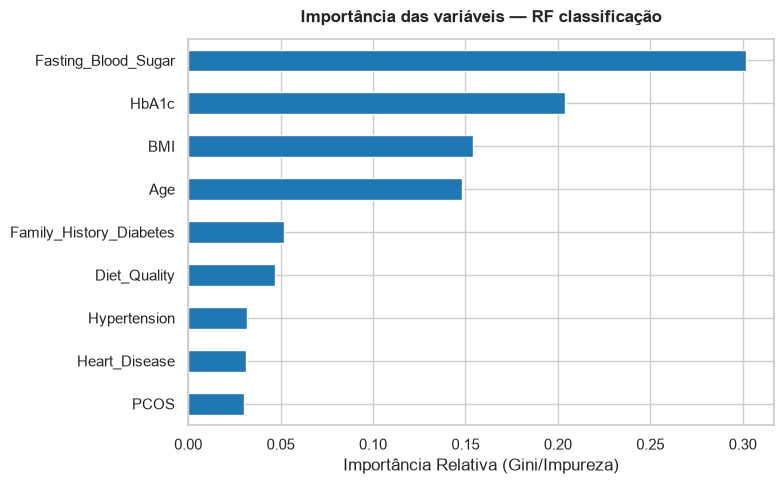

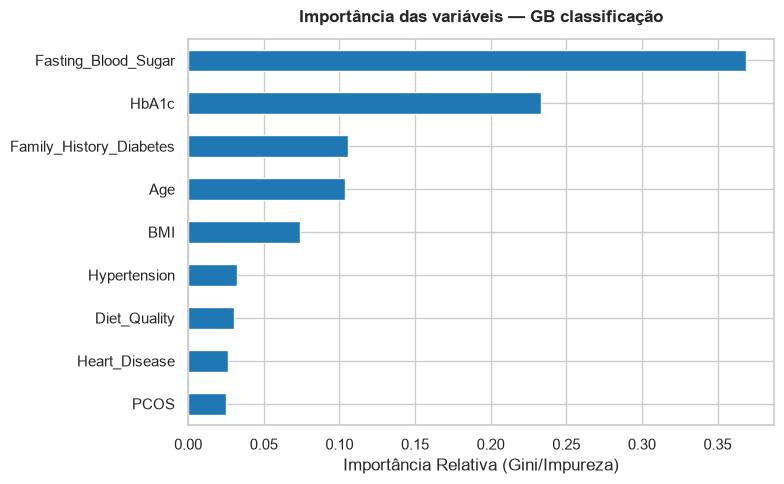

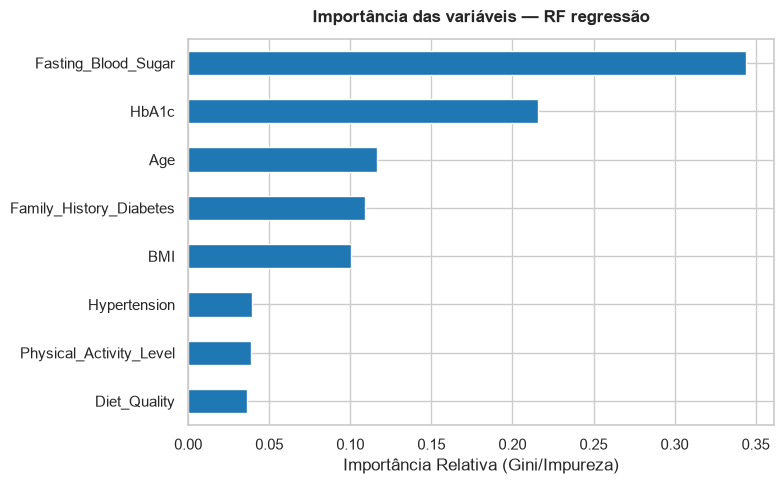

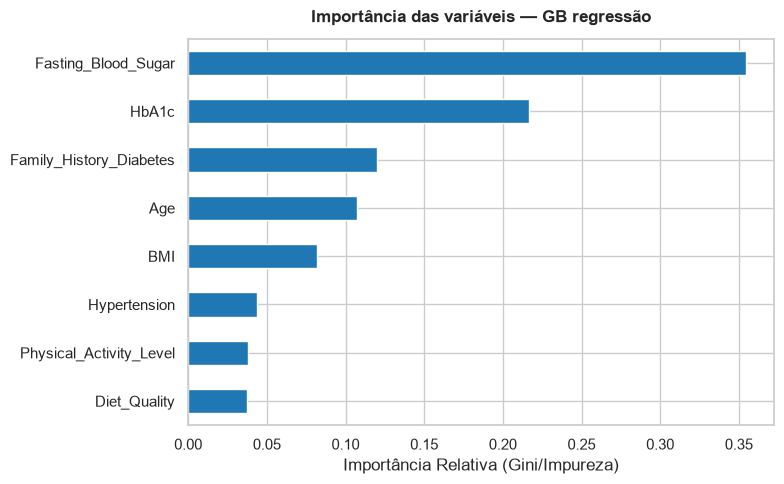

In [8]:
importancias = {
    "RF classificação": importancias_features(rf_c),
    "GB classificação": importancias_features(gb_c),
    "RF regressão": importancias_features(rf_r),
    "GB regressão": importancias_features(gb_r),
}

tabela_importancias = (
    pd.DataFrame(importancias)
    .rename_axis("Feature")
    .reset_index()
)
display(tabela_importancias.round(4))
tabela_importancias.to_csv(
    TABLES_DIR / "importancia_features.csv", index=False, encoding="utf-8"
)

# Nomes de arquivo sem acentos para evitar problemas em sistemas
# operacionais e repositórios que não normalizam Unicode.
nomes_arquivo_importancia = {
    "RF classificação": "importancia_features_rf_classificacao",
    "GB classificação": "importancia_features_gb_classificacao",
    "RF regressão": "importancia_features_rf_regressao",
    "GB regressão": "importancia_features_gb_regressao",
}

for nome, serie in importancias.items():
    plotar_importancia_features(
        serie,
        titulo=f"Importância das variáveis — {nome}",
        arquivo_saida=FIGURES_DIR / f"{nomes_arquivo_importancia[nome]}.png",
    )
    plt.show()

### 5.1 Comparação com as variáveis usadas nas regras do especialista

A tabela abaixo marca quais variáveis aparecem na base de regras. A comparação
é importante porque um ensemble pode usar uma variável apenas como proxy de
outra, enquanto o especialista precisa declarar explicitamente cada condição.

In [9]:
importancia_rf_c = importancias["RF classificação"]
comparacao_c = pd.DataFrame(
    {
        "Feature": FEATURES_CLASSIFICACAO,
        "Usada nas regras (classificação)": [
            f in FEATURES_REGRAS_CLASSIFICACAO for f in FEATURES_CLASSIFICACAO
        ],
        "Importância RF": [importancia_rf_c.get(f, 0.0) for f in FEATURES_CLASSIFICACAO],
    }
)
comparacao_c["Rank RF"] = comparacao_c["Importância RF"].rank(ascending=False).astype(int)
comparacao_c = comparacao_c.sort_values("Importância RF", ascending=False)
display(comparacao_c.round(4))

importancia_rf_r = importancias["RF regressão"]
comparacao_r = pd.DataFrame(
    {
        "Feature": FEATURES_REGRESSAO,
        "Usada nas regras (regressão)": [
            f in FEATURES_REGRAS_REGRESSAO for f in FEATURES_REGRESSAO
        ],
        "Importância RF": [importancia_rf_r.get(f, 0.0) for f in FEATURES_REGRESSAO],
    }
)
comparacao_r["Rank RF"] = comparacao_r["Importância RF"].rank(ascending=False).astype(int)
comparacao_r = comparacao_r.sort_values("Importância RF", ascending=False)
display(comparacao_r.round(4))

pd.concat(
    [
        comparacao_c.assign(Problema="Classificação"),
        comparacao_r.assign(Problema="Regressão"),
    ],
    ignore_index=True,
).to_csv(TABLES_DIR / "comparacao_features_regras.csv", index=False, encoding="utf-8")

,Feature,Usada nas regras (classificação),Importância RF,Rank RF
0,Fasting_Blood_Sugar,True,0.3018,1
1,HbA1c,True,0.2036,2
3,BMI,False,0.1543,3
2,Age,True,0.1479,4
4,Family_History_Diabetes,False,0.0521,5
6,Diet_Quality,False,0.0471,6
5,Hypertension,False,0.0316,7
8,Heart_Disease,False,0.0314,8
7,PCOS,False,0.0302,9


,Feature,Usada nas regras (regressão),Importância RF,Rank RF
0,Fasting_Blood_Sugar,True,0.3441,1
1,HbA1c,True,0.2159,2
2,Age,True,0.1165,3
4,Family_History_Diabetes,True,0.1091,4
3,BMI,True,0.1004,5
5,Hypertension,True,0.0392,6
7,Physical_Activity_Level,True,0.0384,7
6,Diet_Quality,True,0.0363,8


Na classificação, o especialista usa apenas três variáveis (glicemia, HbA1c
e idade). A Random Forest distribui importância também por IMC, histórico
familiar e outras variáveis, mas glicemia e HbA1c permanecem no topo — ou
seja, as regras capturam os fatores dominantes, embora ignorem interações
sutis e a contribuição do IMC. Na regressão, a base v2 usa as oito variáveis;
a Random Forest confirma que glicemia, HbA1c, idade, IMC e histórico são as
mais relevantes, enquanto atividade física, dieta e hipertensão têm peso
menor, mas não desprezível.

## 6. Complexidade dos ensembles

In [10]:
def complexidade_ensemble(modelo, nome: str) -> dict:
    estimador = modelo.named_steps["model"]
    arvores = np.ravel(estimador.estimators_)
    nos = sum(arvore.tree_.node_count for arvore in arvores)
    profundidade = max(arvore.tree_.max_depth for arvore in arvores)
    return {
        "Modelo": nome,
        "Árvores": len(arvores),
        "Nós totais": int(nos),
        "Profundidade máxima": int(profundidade),
    }

complexidades = pd.DataFrame(
    [
        complexidade_ensemble(rf_c, "RF classificação"),
        complexidade_ensemble(gb_c, "GB classificação"),
        complexidade_ensemble(rf_r, "RF regressão"),
        complexidade_ensemble(gb_r, "GB regressão"),
    ]
)
display(complexidades)
complexidades.to_csv(
    TABLES_DIR / "complexidade_ensemble.csv", index=False, encoding="utf-8"
)

,Modelo,Árvores,Nós totais,Profundidade máxima
0,RF classificação,100,823112,29
1,GB classificação,600,9000,3
2,RF regressão,200,1592532,28
3,GB regressão,200,1400,2
